# 01 — Praproses Citra
**Proyek:** Klasifikasi penyakit daun cabai (Warna HSV + Tekstur GLCM + SVM)

Alur notebook ini (per citra):
1. Resize ke **512×512**, rasio dijaga (sisa ruang diisi **padding hitam**)
2. **Gaussian filtering 5×5** (mengurangi noise)
3. Peningkatan kontras pada kanal **L (LAB)** — dibandingkan dulu **Histogram Equalization (HE)** vs **CLAHE**, lalu dipilih satu
4. Simpan ke `output/01_praproses/<kelas>/`

> Urutan di kode: resize → Gaussian → equalization → padding. Padding hitam dipasang **terakhir** supaya piksel hitam tidak ikut mengacaukan histogram/tile CLAHE.

In [1]:
from pathlib import Path
import json, random
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from IPython.display import display
try:
    from tqdm.auto import tqdm
except ImportError:
    tqdm = lambda x, **k: x

SEED = 42
random.seed(SEED); np.random.seed(SEED)

# Root proyek = folder pcv_bkpm (otomatis, baik dijalankan dari notebooks/ maupun root)
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
DATA = ROOT / "dataset_crop"      # input: citra daun hasil crop, 1 subfolder = 1 kelas
OUT  = ROOT / "output"            # semua hasil notebook disimpan di sini
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
CLASSES = sorted(p.name for p in DATA.iterdir() if p.is_dir())   # label = nama subfolder

def imread(path, flags=cv2.IMREAD_COLOR):          # aman untuk path Windows ber-spasi/non-ASCII
    return cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), flags)

def imwrite(path, img):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    ok, buf = cv2.imencode(path.suffix, img); buf.tofile(str(path)); return ok

def list_images(folder):
    return sorted(p for p in Path(folder).iterdir() if p.suffix.lower() in IMG_EXT)

def rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

print("ROOT   :", ROOT)
print("Kelas  :", CLASSES)

ROOT   : D:\SEMESTER 5\pcv_bkpm
Kelas  : ['bercak_daun', 'sehat', 'ulat', 'virus_gemini']


c:\Users\Shobri\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Inventaris dataset

,kelas,jumlah,persen
0,bercak_daun,50,20.8
1,sehat,50,20.8
2,ulat,50,20.8
3,virus_gemini,90,37.5


Total citra: 240


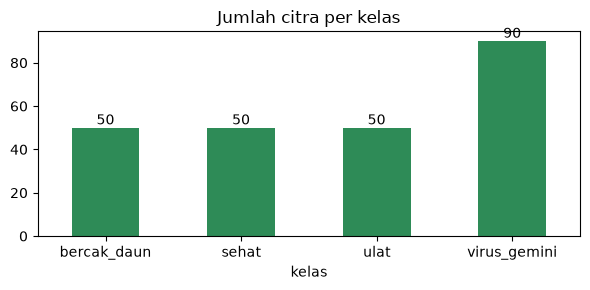

In [2]:
rows = [{"kelas": c, "jumlah": len(list_images(DATA / c))} for c in CLASSES]
df_count = pd.DataFrame(rows)
df_count["persen"] = (df_count.jumlah / df_count.jumlah.sum() * 100).round(1)
display(df_count)
print("Total citra:", df_count.jumlah.sum())

ax = df_count.plot.bar(x="kelas", y="jumlah", legend=False, figsize=(6, 3), color="seagreen")
ax.bar_label(ax.containers[0]); plt.title("Jumlah citra per kelas"); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

In [3]:
# Ukuran asli citra (contoh maks. 20 per kelas)
sizes = []
for c in CLASSES:
    for p in list_images(DATA / c)[:20]:
        im = imread(p)
        sizes.append((c, im.shape[1], im.shape[0]))
df_size = pd.DataFrame(sizes, columns=["kelas", "lebar", "tinggi"])
display(df_size.groupby("kelas").agg(["min", "max", "mean"]).round(0))

lebar               tinggi              
               min   max    mean    min   max    mean
kelas                                                
bercak_daun    601  3407  1876.0    828  4000  1985.0
sehat         1000  2992  2197.0   1000  3592  2156.0
ulat           285  3468  1596.0    244  4624  1676.0
virus_gemini  1870  2992  2803.0    761  3219  2533.0

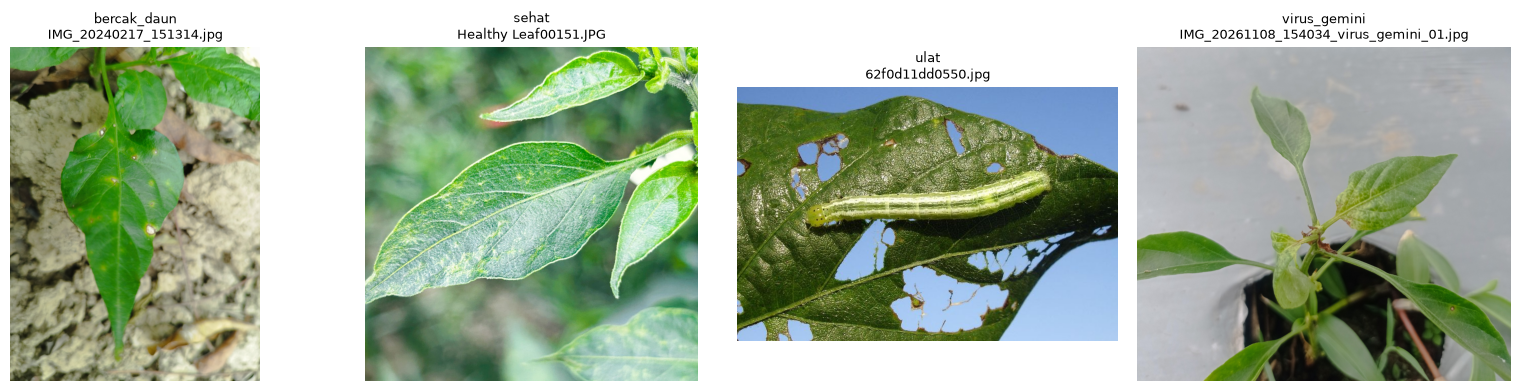

In [4]:
# Preview 1 citra asli per kelas
fig, axes = plt.subplots(1, len(CLASSES), figsize=(4 * len(CLASSES), 4))
axes = np.atleast_1d(axes)
for ax, c in zip(axes, CLASSES):
    p = list_images(DATA / c)[0]
    ax.imshow(rgb(imread(p))); ax.set_title(f"{c}\n{p.name}", fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

## 2. Resize 512×512 (rasio dijaga) + padding hitam

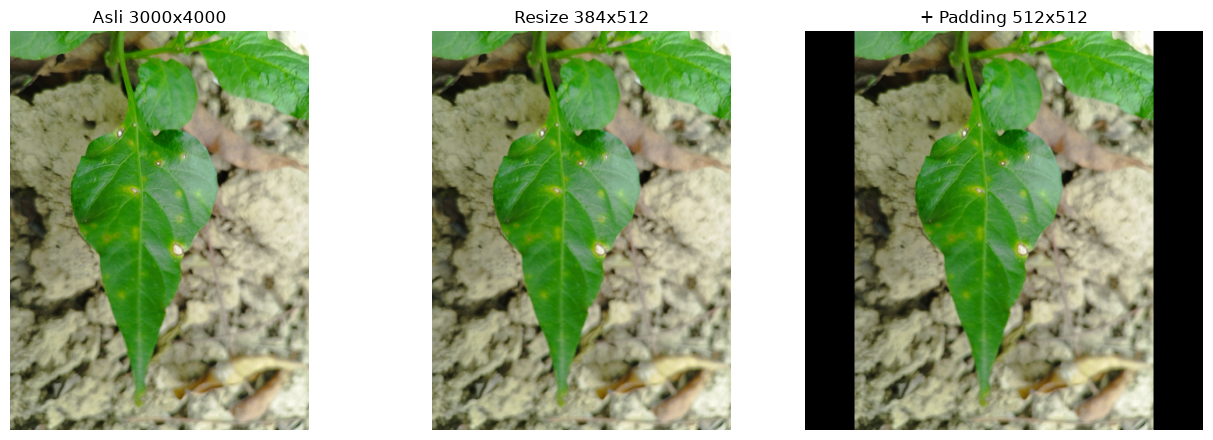

In [5]:
SIZE = 512

def resize_keep_ratio(img, size=SIZE):
    """Skala sisi terpanjang jadi `size`, rasio asli tetap."""
    h, w = img.shape[:2]
    s = size / max(h, w)
    interp = cv2.INTER_AREA if s < 1 else cv2.INTER_CUBIC
    return cv2.resize(img, (max(1, round(w * s)), max(1, round(h * s))), interpolation=interp)

def pad_black(img, size=SIZE):
    """Padding hitam simetris sampai size x size."""
    h, w = img.shape[:2]
    top, left = (size - h) // 2, (size - w) // 2
    return cv2.copyMakeBorder(img, top, size - h - top, left, size - w - left,
                              cv2.BORDER_CONSTANT, value=(0, 0, 0))

# Demo: sampel dari kelas pertama
DEMO_PATH = list_images(DATA / CLASSES[0])[0]
raw = imread(DEMO_PATH)
resized = resize_keep_ratio(raw)
padded_only = pad_black(resized)

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
for ax, im, t in zip(axes, [raw, resized, padded_only],
                     [f"Asli {raw.shape[1]}x{raw.shape[0]}", f"Resize {resized.shape[1]}x{resized.shape[0]}",
                      f"+ Padding {padded_only.shape[1]}x{padded_only.shape[0]}"]):
    ax.imshow(rgb(im)); ax.set_title(t); ax.axis("off")
plt.tight_layout(); plt.show()

## 3. Gaussian filtering 5×5

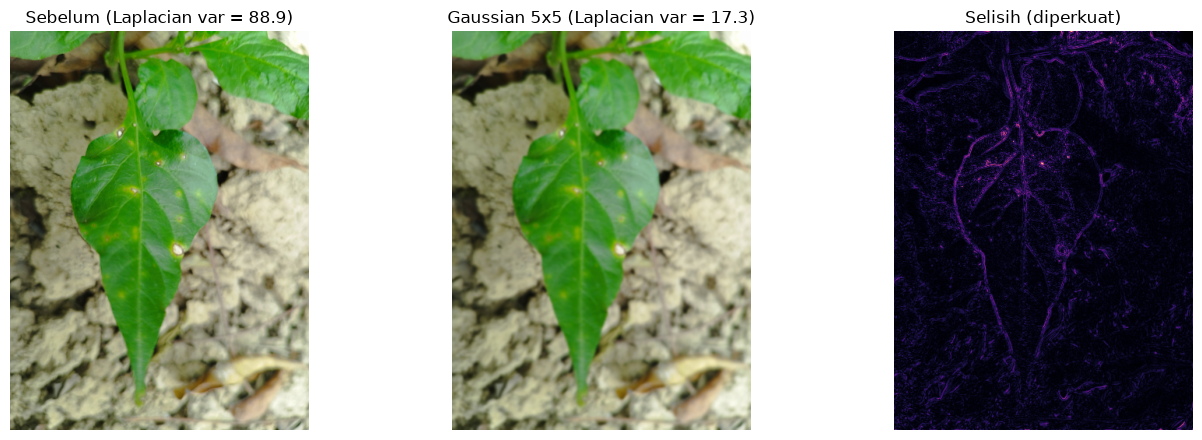

In [6]:
GAUSS_K = (5, 5)
blur = cv2.GaussianBlur(resized, GAUSS_K, 0)

def lap_var(im):   # makin kecil = makin halus / noise berkurang
    return cv2.Laplacian(cv2.cvtColor(im, cv2.COLOR_BGR2GRAY), cv2.CV_64F).var()

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
axes[0].imshow(rgb(resized)); axes[0].set_title(f"Sebelum (Laplacian var = {lap_var(resized):.1f})")
axes[1].imshow(rgb(blur));    axes[1].set_title(f"Gaussian 5x5 (Laplacian var = {lap_var(blur):.1f})")
diff = cv2.absdiff(resized, blur).max(axis=2)
axes[2].imshow(diff, cmap="magma"); axes[2].set_title("Selisih (diperkuat)")
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

## 4. Equalization kanal L (LAB): HE vs CLAHE
Konversi ke LAB, hanya kanal **L** (kecerahan) yang diubah supaya warna (a, b) tidak bergeser — penting karena fitur akhir berbasis warna.

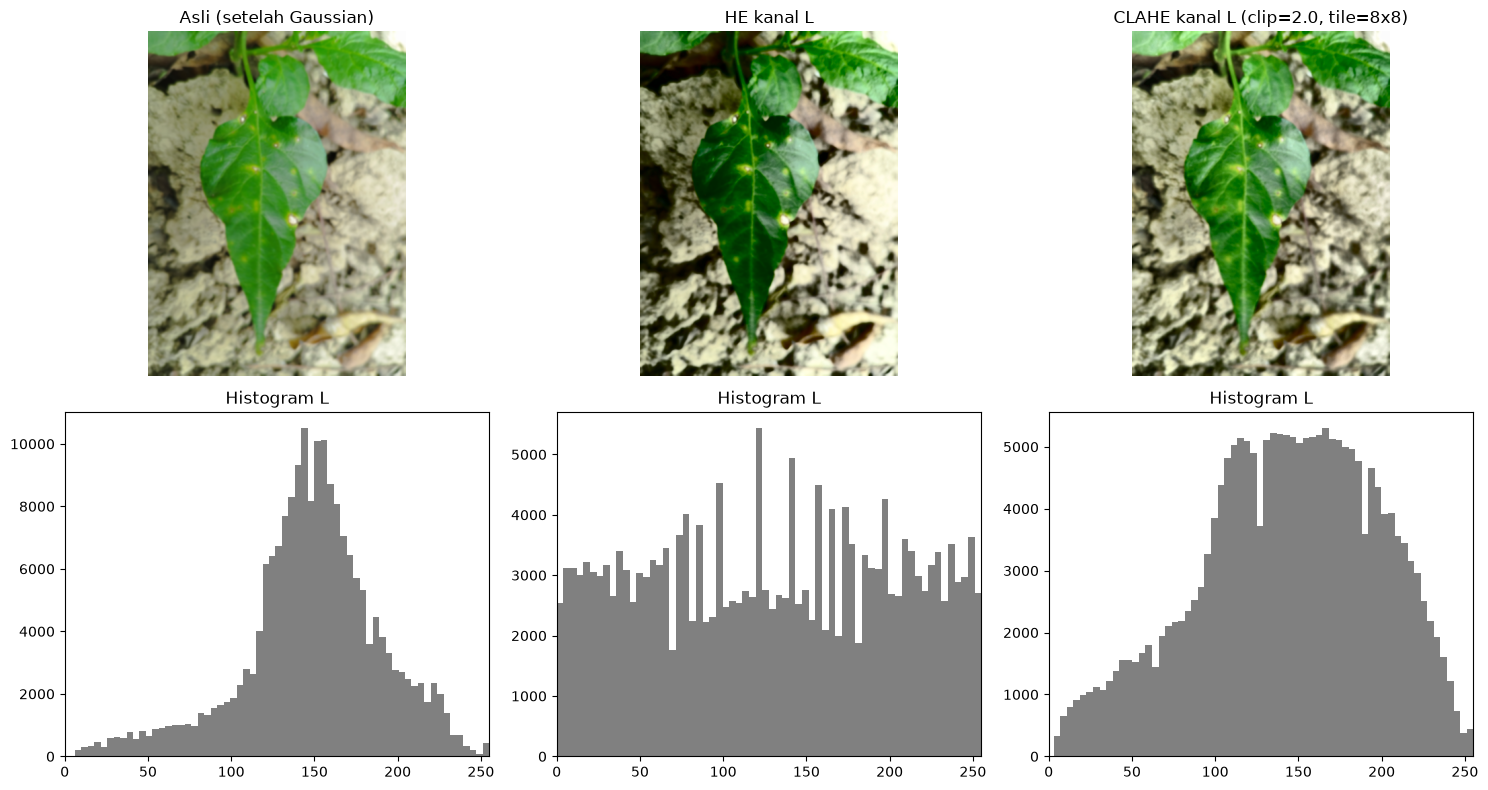

,metode,mean_L,std_L (kontras),entropi_L
0,Asli,148.44,41.44,7.32
1,HE,128.53,73.66,7.06
2,CLAHE,143.17,54.14,7.74


In [7]:
CLAHE_CLIP, CLAHE_TILE = 2.0, (8, 8)

def entropy(gray):
    p = np.bincount(gray.ravel(), minlength=256).astype(float); p /= p.sum(); p = p[p > 0]
    return float(-(p * np.log2(p)).sum())

lab = cv2.cvtColor(blur, cv2.COLOR_BGR2LAB)
L, A, B = cv2.split(lab)
L_he = cv2.equalizeHist(L)
L_cl = cv2.createCLAHE(clipLimit=CLAHE_CLIP, tileGridSize=CLAHE_TILE).apply(L)

def back(L2):
    return cv2.cvtColor(cv2.merge([L2, A, B]), cv2.COLOR_LAB2BGR)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for j, (im, t, Lx) in enumerate([(blur, "Asli (setelah Gaussian)", L), (back(L_he), "HE kanal L", L_he),
                                 (back(L_cl), f"CLAHE kanal L (clip={CLAHE_CLIP}, tile={CLAHE_TILE[0]}x{CLAHE_TILE[1]})", L_cl)]):
    axes[0, j].imshow(rgb(im)); axes[0, j].set_title(t); axes[0, j].axis("off")
    axes[1, j].hist(Lx.ravel(), bins=64, color="gray"); axes[1, j].set_title("Histogram L"); axes[1, j].set_xlim(0, 255)
plt.tight_layout(); plt.show()

df_eq = pd.DataFrame({
    "metode": ["Asli", "HE", "CLAHE"],
    "mean_L": [L.mean(), L_he.mean(), L_cl.mean()],
    "std_L (kontras)": [L.std(), L_he.std(), L_cl.std()],
    "entropi_L": [entropy(L), entropy(L_he), entropy(L_cl)],
}).round(2)
display(df_eq)

**Keputusan: pakai CLAHE.**
HE bekerja global — satu transformasi untuk seluruh citra — sehingga cenderung mengubah kecerahan keseluruhan secara drastis, memperkuat noise, dan bisa membuat area lesi/bercak "terbakar". CLAHE bekerja per-tile dengan batas `clipLimit`, jadi kontras lokal naik (bercak, tepi lesi lebih jelas) tanpa ledakan noise. Kamu bisa membandingkan angka std/entropi dan gambar di atas untuk citra lain dengan mengganti `DEMO_PATH`.

Kalau mau mencoba HE untuk perbandingan di laporan, cukup ubah `EQ_METHOD = "he"` di sel berikutnya.

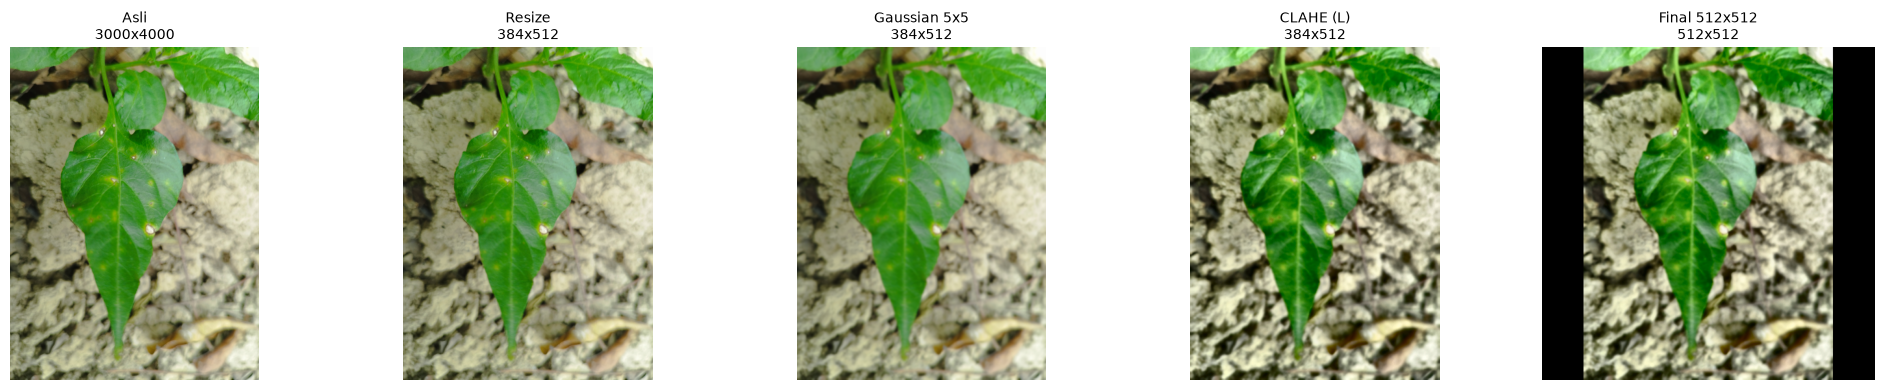

In [8]:
EQ_METHOD = "clahe"      # "clahe" (dipakai) | "he"

def equalize_L(img_bgr, method=EQ_METHOD):
    L, A, B = cv2.split(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB))
    if method == "clahe":
        L2 = cv2.createCLAHE(clipLimit=CLAHE_CLIP, tileGridSize=CLAHE_TILE).apply(L)
    else:
        L2 = cv2.equalizeHist(L)
    return cv2.cvtColor(cv2.merge([L2, A, B]), cv2.COLOR_LAB2BGR)

def preprocess(img):
    x = resize_keep_ratio(img)           # 1. resize (rasio dijaga)
    x = cv2.GaussianBlur(x, GAUSS_K, 0)  # 2. Gaussian 5x5
    x = equalize_L(x)                    # 3. CLAHE di kanal L
    return pad_black(x)                  # 4. padding hitam -> 512x512

# Demo seluruh tahapan pada 1 citra
stages = [("Asli", raw), ("Resize", resized), ("Gaussian 5x5", blur),
          (f"{EQ_METHOD.upper()} (L)", equalize_L(blur)), ("Final 512x512", preprocess(raw))]
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, (t, im) in zip(axes, stages):
    ax.imshow(rgb(im)); ax.set_title(f"{t}\n{im.shape[1]}x{im.shape[0]}", fontsize=10); ax.axis("off")
plt.tight_layout(); plt.show()

## 5. Proses seluruh dataset → `output/01_praproses/<kelas>/`

In [9]:
OUT_PRE = OUT / "01_praproses"
records = []
for c in CLASSES:
    for p in tqdm(list_images(DATA / c), desc=c):
        img = imread(p)
        if img is None:
            records.append({"kelas": c, "file": p.name, "ok": False, "ukuran": None}); continue
        res = preprocess(img)
        imwrite(OUT_PRE / c / (p.stem + ".png"), res)    # PNG = lossless
        records.append({"kelas": c, "file": p.name, "ok": True, "ukuran": res.shape})

df_rec = pd.DataFrame(records)
display(df_rec.groupby("kelas").agg(total=("file", "count"), berhasil=("ok", "sum")))
print("Semua ukuran 512x512 (3 kanal):", all(s == (512, 512, 3) for s in df_rec.ukuran.dropna()))
print("Gagal dibaca:", int((~df_rec.ok).sum()))
print("Disimpan di:", OUT_PRE)

virus_gemini: 100%|██████████| 90/90 [00:10<00:00,  8.44it/s]


,total,berhasil
kelas,,
bercak_daun,50,50
sehat,50,50
ulat,50,50
virus_gemini,90,90


Semua ukuran 512x512 (3 kanal): True
Gagal dibaca: 0
Disimpan di: D:\SEMESTER 5\pcv_bkpm\output\01_praproses


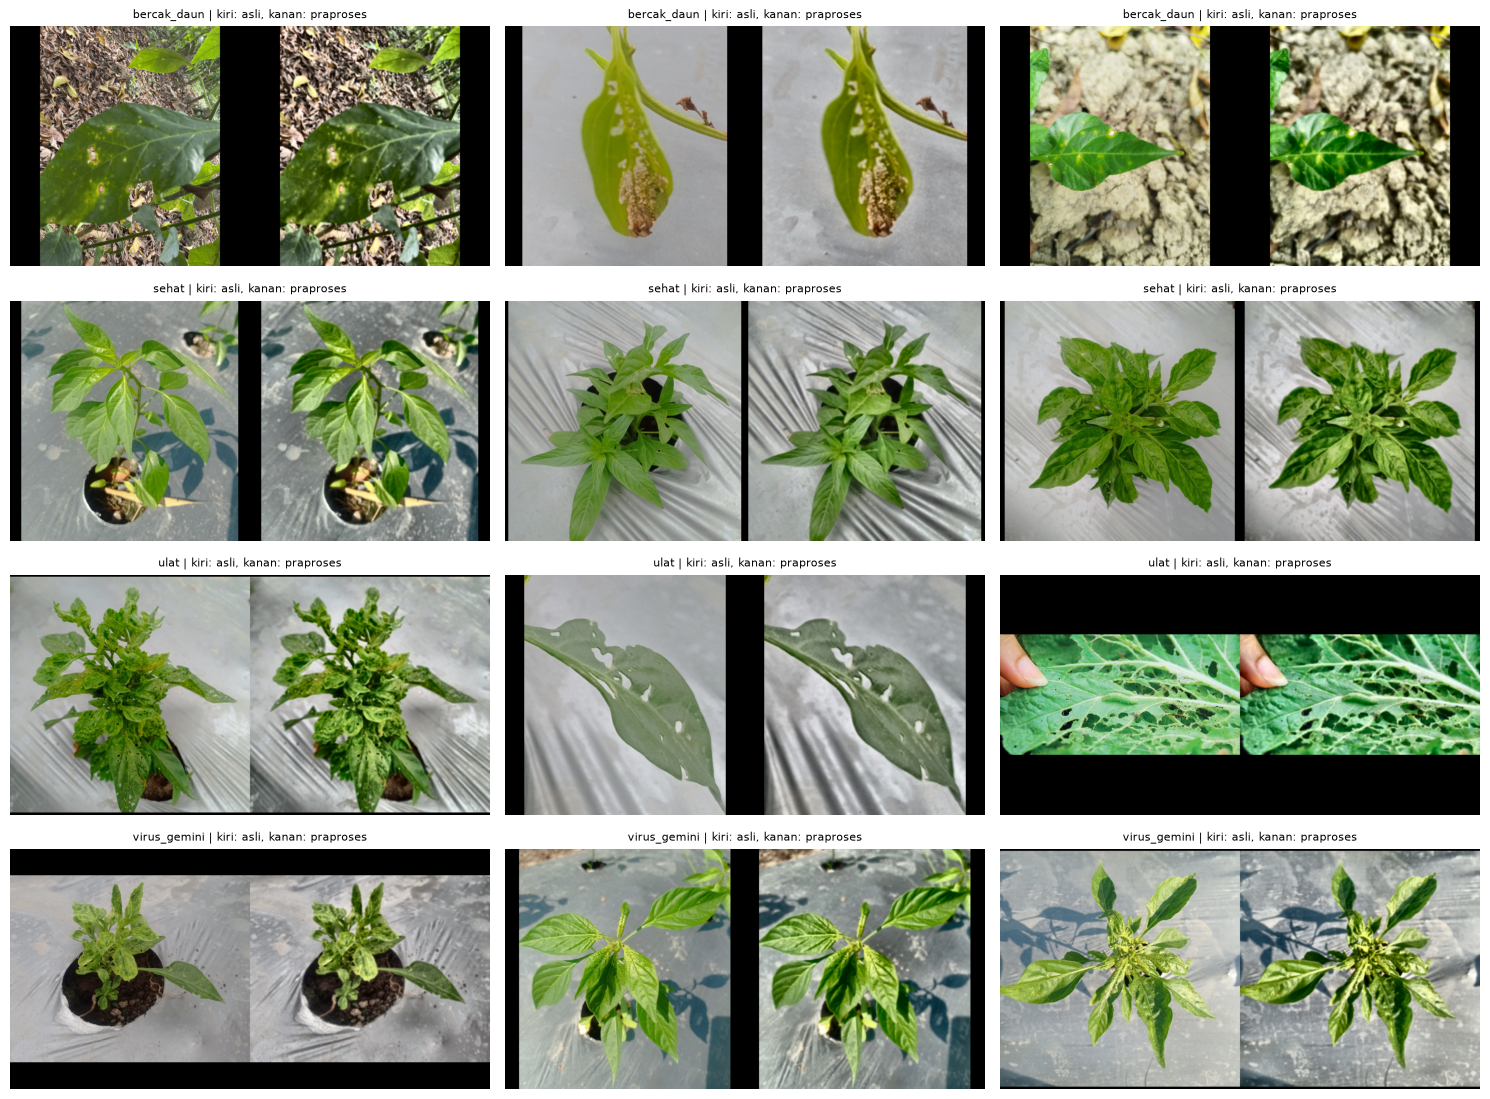

In [10]:
# Preview per kelas: kiri = asli (resize+padding saja), kanan = hasil praproses
N_PREVIEW = 3
rng = random.Random(SEED)
fig, axes = plt.subplots(len(CLASSES), N_PREVIEW, figsize=(5 * N_PREVIEW, 2.8 * len(CLASSES)))
axes = np.atleast_2d(axes)
for i, c in enumerate(CLASSES):
    files = rng.sample(list_images(DATA / c), min(N_PREVIEW, len(list_images(DATA / c))))
    for j in range(N_PREVIEW):
        ax = axes[i, j]; ax.axis("off")
        if j < len(files):
            before = pad_black(resize_keep_ratio(imread(files[j])))
            after = imread(OUT_PRE / c / (files[j].stem + ".png"))
            ax.imshow(rgb(np.hstack([before, after])))
            ax.set_title(f"{c} | kiri: asli, kanan: praproses", fontsize=8)
plt.tight_layout(); plt.show()